<a href="https://colab.research.google.com/github/teju917/Machine_learning_lab2/blob/main/Program_9_%E2%80%93_Bayesian_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ORIGINAL DATASET
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2  

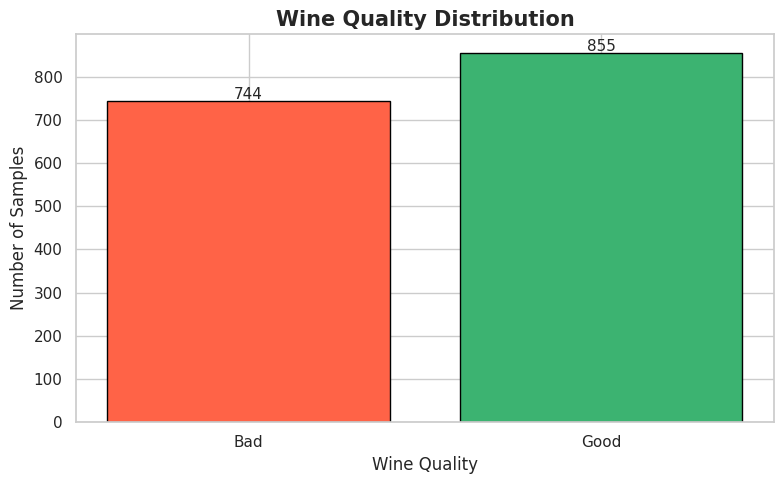

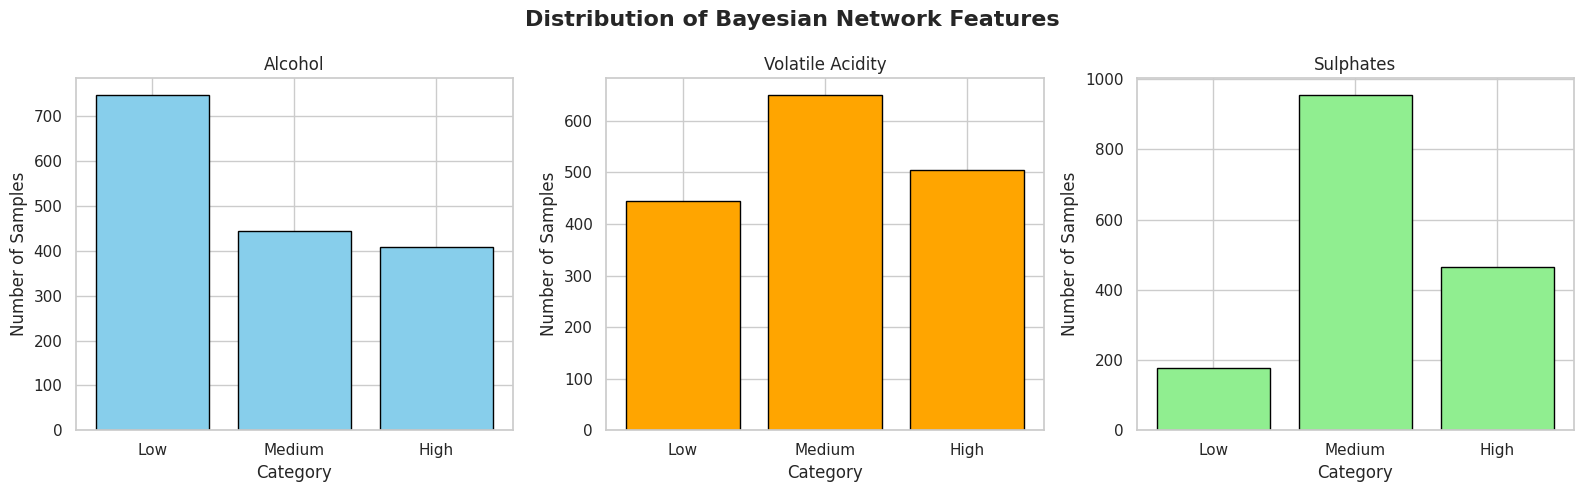


BAYESIAN NETWORK STRUCTURE CREATED


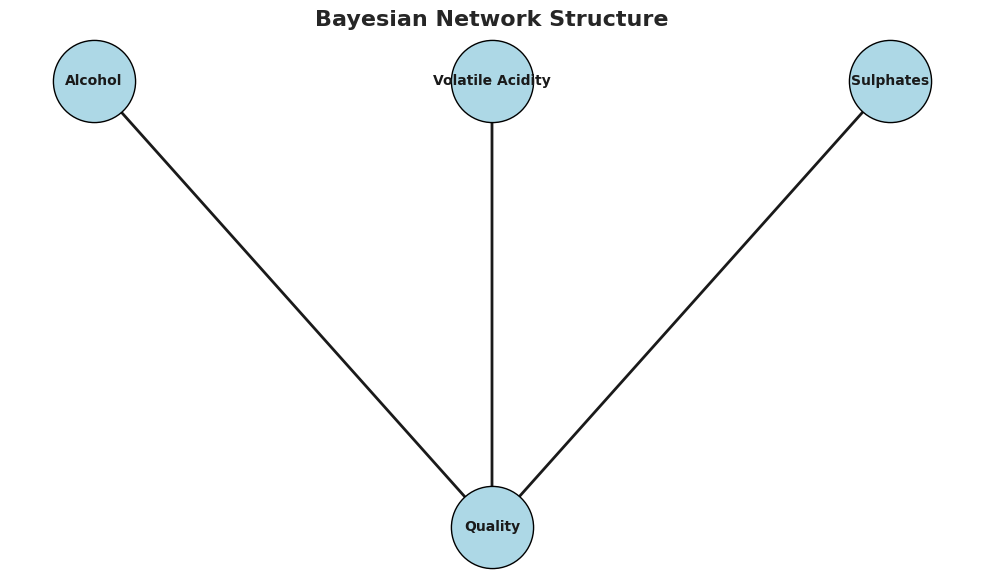


BAYESIAN NETWORK TRAINED SUCCESSFULLY

MODEL VALIDATION: True

CONDITIONAL PROBABILITY TABLES

 +-----------------+----------+
| alcohol(High)   | 0.255645 |
+-----------------+----------+
| alcohol(Low)    | 0.466335 |
+-----------------+----------+
| alcohol(Medium) | 0.278019 |
+-----------------+----------+

 +------------------+-----+--------------------------+
| alcohol          | ... | alcohol(Medium)          |
+------------------+-----+--------------------------+
| sulphates        | ... | sulphates(Medium)        |
+------------------+-----+--------------------------+
| volatile_acidity | ... | volatile_acidity(Medium) |
+------------------+-----+--------------------------+
| quality(Bad)     | ... | 0.3500450315220654       |
+------------------+-----+--------------------------+
| quality(Good)    | ... | 0.6499549684779345       |
+------------------+-----+--------------------------+

 +--------------------------+----------+
| volatile_acidity(High)   | 0.31531  |
+-------

/tmp/ipykernel_1719/2002577626.py:248: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(


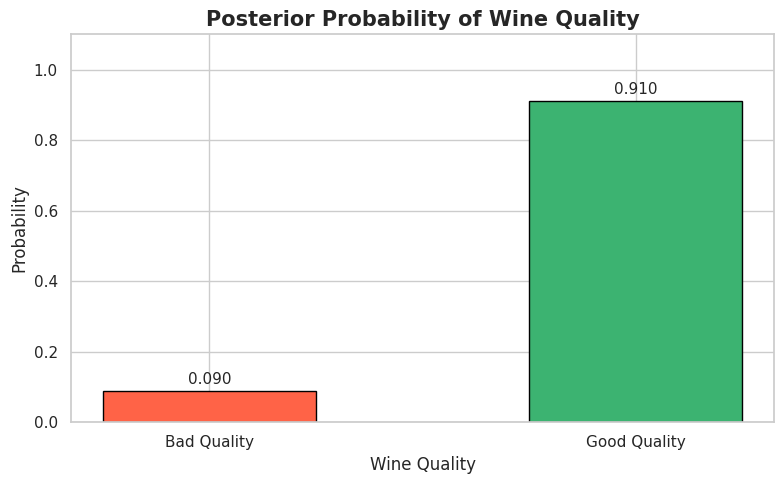

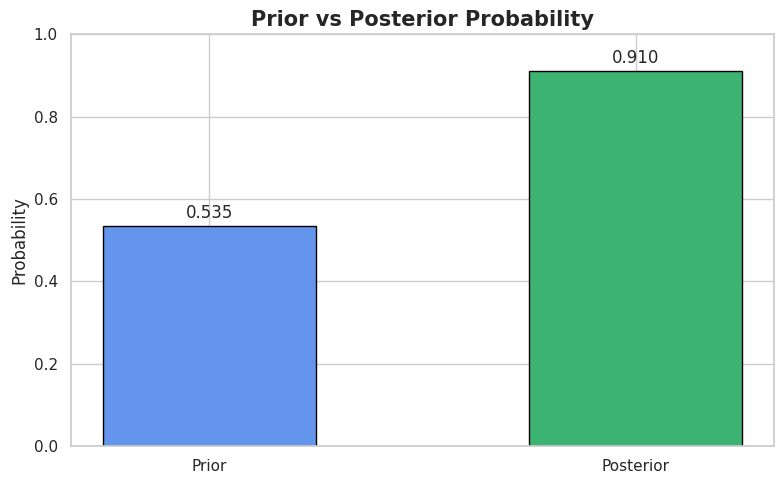


CONDITIONAL PROBABILITY TABLE
           Low  Medium    High
Low     0.5306  0.3569  0.2262
Medium  0.6714  0.5830  0.4351
High    0.9105  0.8027  0.7105


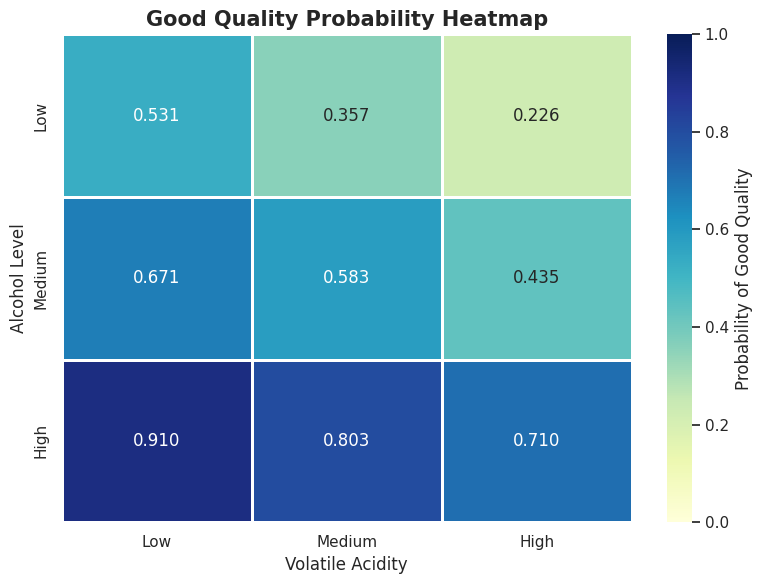


SULPHATES IMPACT
  Sulphates  Good Quality Probability
0       Low                  0.839196
1    Medium                  0.900561
2      High                  0.958293


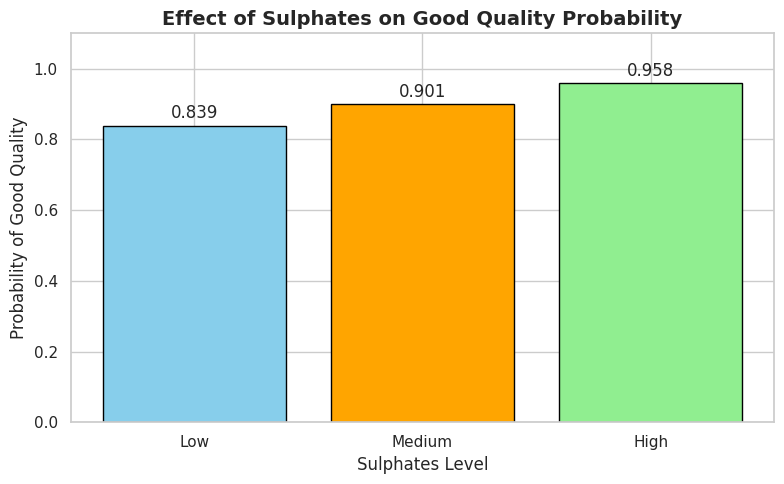


FINAL RESULT
1. Dataset loaded successfully from UCI URL.
2. Data preprocessing completed.
3. Bayesian Network constructed successfully.
4. Conditional Probability Tables generated.
5. Bayesian inference performed successfully.
6. Probability of Good Quality: 91.05 %
7. Network structure visualized.
8. Conditional probability heatmap generated.
9. Prior and posterior probabilities compared.
10. Sulphates impact analyzed.

BAYESIAN NETWORK IMPLEMENTATION COMPLETED.


In [3]:

# ============================================================
# PROGRAM 9: BAYESIAN NETWORKS
# ============================================================

# 1. INSTALL LIBRARIES

!pip install -q pgmpy pandas numpy matplotlib seaborn networkx

# 2. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

sns.set_theme(style="whitegrid")

# ============================================================
# 3. READ DATASET FROM URL
# ============================================================

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("=" * 65)
print("ORIGINAL DATASET")
print("=" * 65)

print(df.head())

print("\nDATASET INFORMATION")
print("Total examples:", len(df))
print("Number of columns:", len(df.columns))

print("\nMISSING VALUES")
print(df.isnull().sum().sum())

print("\nQUALITY DISTRIBUTION")
print(df["quality"].value_counts().sort_index())

# ============================================================
# 4. DATA PREPROCESSING
# ============================================================

data = pd.DataFrame()

# Convert alcohol into categories

data["alcohol"] = pd.cut(
    df["alcohol"],
    bins=[-np.inf, 10, 11, np.inf],
    labels=["Low", "Medium", "High"]
)

# Convert volatile acidity into categories

data["volatile_acidity"] = pd.cut(
    df["volatile acidity"],
    bins=[-np.inf, 0.4, 0.6, np.inf],
    labels=["Low", "Medium", "High"]
)

# Convert sulphates into categories

data["sulphates"] = pd.cut(
    df["sulphates"],
    bins=[-np.inf, 0.5, 0.7, np.inf],
    labels=["Low", "Medium", "High"]
)

# Convert quality into Good and Bad

data["quality"] = np.where(
    df["quality"] >= 6,
    "Good",
    "Bad"
)

data = data.dropna().reset_index(drop=True)

print("\nPREPROCESSED DATASET")
print(data.head())

print("\nDATASET SHAPE:", data.shape)

print("\nQUALITY DISTRIBUTION")
print(data["quality"].value_counts())

# ============================================================
# 5. VISUALIZATION 1: WINE QUALITY DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

quality_counts = data["quality"].value_counts().reindex(
    ["Bad", "Good"]
)

bars = plt.bar(
    quality_counts.index,
    quality_counts.values,
    color=["tomato", "mediumseagreen"],
    edgecolor="black"
)

plt.title(
    "Wine Quality Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Wine Quality")
plt.ylabel("Number of Samples")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        int(bar.get_height()),
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

# ============================================================
# 6. VISUALIZATION 2: FEATURE DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

features = [
    "alcohol",
    "volatile_acidity",
    "sulphates"
]

colors = ["skyblue", "orange", "lightgreen"]

for i, feature in enumerate(features):

    counts = data[feature].value_counts().reindex(
        ["Low", "Medium", "High"],
        fill_value=0
    )

    axes[i].bar(
        counts.index,
        counts.values,
        color=colors[i],
        edgecolor="black"
    )

    axes[i].set_title(
        feature.replace("_", " ").title()
    )

    axes[i].set_xlabel("Category")
    axes[i].set_ylabel("Number of Samples")

fig.suptitle(
    "Distribution of Bayesian Network Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ============================================================
# 7. CREATE BAYESIAN NETWORK
# ============================================================

model = DiscreteBayesianNetwork([
    ("alcohol", "quality"),
    ("volatile_acidity", "quality"),
    ("sulphates", "quality")
])

print("\nBAYESIAN NETWORK STRUCTURE CREATED")

# ============================================================
# 8. VISUALIZATION 3: BAYESIAN NETWORK STRUCTURE
# ============================================================

G = nx.DiGraph()

G.add_edges_from([
    ("Alcohol", "Quality"),
    ("Volatile Acidity", "Quality"),
    ("Sulphates", "Quality")
])

plt.figure(figsize=(10, 6))

pos = {
    "Alcohol": (0, 2),
    "Volatile Acidity": (2, 2),
    "Sulphates": (4, 2),
    "Quality": (2, 0)
}

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=3500,
    node_color="lightblue",
    edgecolors="black"
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=25,
    width=2,
    connectionstyle="arc3,rad=0.0"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold"
)

plt.title(
    "Bayesian Network Structure",
    fontsize=16,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()

# ============================================================
# 9. TRAIN BAYESIAN NETWORK
# ============================================================

estimator = BayesianEstimator(
    model=model,
    data=data
)

cpds = estimator.get_parameters(
    prior_type="BDeu",
    equivalent_sample_size=10
)

model.add_cpds(*cpds)

print("\nBAYESIAN NETWORK TRAINED SUCCESSFULLY")

print("\nMODEL VALIDATION:", model.check_model())

# ============================================================
# 10. DISPLAY CONDITIONAL PROBABILITY TABLES
# ============================================================

print("\n" + "=" * 65)
print("CONDITIONAL PROBABILITY TABLES")
print("=" * 65)

for cpd in model.get_cpds():
    print("\n", cpd)

# ============================================================
# 11. BAYESIAN INFERENCE
# ============================================================

inference = VariableElimination(model)

result = inference.query(
    variables=["quality"],
    evidence={
        "alcohol": "High",
        "volatile_acidity": "Low"
    },
    show_progress=False
)

print("\n" + "=" * 65)
print("BAYESIAN INFERENCE RESULTS")
print("=" * 65)

print("Evidence:")
print("Alcohol = High")
print("Volatile Acidity = Low")

print("\nINFERENCE RESULT")
print(result)

# ============================================================
# 12. CALCULATE EVENT PROBABILITY
# ============================================================

quality_states = list(result.state_names["quality"])

good_index = quality_states.index("Good")
bad_index = quality_states.index("Bad")

good_probability = float(result.values[good_index])
bad_probability = float(result.values[bad_index])

print("\nEVENT PROBABILITY")

print(
    "Probability of Good Quality:",
    round(good_probability, 4)
)

print(
    "Good Quality Percentage:",
    round(good_probability * 100, 2), "%"
)

print(
    "Probability of Bad Quality:",
    round(bad_probability, 4)
)

print(
    "Bad Quality Percentage:",
    round(bad_probability * 100, 2), "%"
)

# ============================================================
# 13. VISUALIZATION 4: EVENT PROBABILITY
# ============================================================

plt.figure(figsize=(8, 5))

probabilities = [
    bad_probability,
    good_probability
]

labels = [
    "Bad Quality",
    "Good Quality"
]

bars = plt.bar(
    labels,
    probabilities,
    color=["tomato", "mediumseagreen"],
    edgecolor="black",
    width=0.5
)

plt.title(
    "Posterior Probability of Wine Quality",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Wine Quality")
plt.ylabel("Probability")

plt.ylim(0, 1.1)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{bar.get_height():.3f}",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

# ============================================================
# 14. VISUALIZATION 5: PRIOR VS POSTERIOR PROBABILITY
# ============================================================

prior_good = float(
    (data["quality"] == "Good").mean()
)

comparison = pd.DataFrame({
    "Probability Type": ["Prior", "Posterior"],
    "Good Quality Probability": [
        prior_good,
        good_probability
    ]
})

plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison["Probability Type"],
    comparison["Good Quality Probability"],
    color=["cornflowerblue", "mediumseagreen"],
    edgecolor="black",
    width=0.5
)

plt.title(
    "Prior vs Posterior Probability",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Probability")
plt.ylim(0, 1)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# ============================================================
# 15. VISUALIZATION 6: CONDITIONAL PROBABILITY HEATMAP
# ============================================================

alcohol_levels = ["Low", "Medium", "High"]
acidity_levels = ["Low", "Medium", "High"]

probability_matrix = []

for alcohol in alcohol_levels:

    row = []

    for acidity in acidity_levels:

        prediction = inference.query(
            variables=["quality"],
            evidence={
                "alcohol": alcohol,
                "volatile_acidity": acidity
            },
            show_progress=False
        )

        states = list(prediction.state_names["quality"])
        index = states.index("Good")

        probability = float(prediction.values[index])

        row.append(probability)

    probability_matrix.append(row)

probability_df = pd.DataFrame(
    probability_matrix,
    index=alcohol_levels,
    columns=acidity_levels
)

print("\nCONDITIONAL PROBABILITY TABLE")
print(probability_df.round(4))

plt.figure(figsize=(8, 6))

sns.heatmap(
    probability_df,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=1,
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Probability of Good Quality"}
)

plt.title(
    "Good Quality Probability Heatmap",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Volatile Acidity")
plt.ylabel("Alcohol Level")

plt.tight_layout()
plt.show()

# ============================================================
# 16. VISUALIZATION 7: SULPHATES IMPACT
# ============================================================

sulphates_levels = ["Low", "Medium", "High"]
sulphates_probabilities = []

for sulphates in sulphates_levels:

    prediction = inference.query(
        variables=["quality"],
        evidence={
            "alcohol": "High",
            "volatile_acidity": "Low",
            "sulphates": sulphates
        },
        show_progress=False
    )

    states = list(prediction.state_names["quality"])
    index = states.index("Good")

    sulphates_probabilities.append(
        float(prediction.values[index])
    )

sulphates_df = pd.DataFrame({
    "Sulphates": sulphates_levels,
    "Good Quality Probability": sulphates_probabilities
})

print("\nSULPHATES IMPACT")
print(sulphates_df)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    sulphates_df["Sulphates"],
    sulphates_df["Good Quality Probability"],
    color=["skyblue", "orange", "lightgreen"],
    edgecolor="black"
)

plt.title(
    "Effect of Sulphates on Good Quality Probability",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Sulphates Level")
plt.ylabel("Probability of Good Quality")
plt.ylim(0, 1.1)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# ============================================================
# 17. FINAL RESULT
# ============================================================

print("\n" + "=" * 65)
print("FINAL RESULT")
print("=" * 65)

print("1. Dataset loaded successfully from UCI URL.")
print("2. Data preprocessing completed.")
print("3. Bayesian Network constructed successfully.")
print("4. Conditional Probability Tables generated.")
print("5. Bayesian inference performed successfully.")

print(
    "6. Probability of Good Quality:",
    round(good_probability * 100, 2), "%"
)

print("7. Network structure visualized.")
print("8. Conditional probability heatmap generated.")
print("9. Prior and posterior probabilities compared.")
print("10. Sulphates impact analyzed.")

print("\nBAYESIAN NETWORK IMPLEMENTATION COMPLETED.")
